### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [56]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np

In [57]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

# Setosa와 Versicolor만 선택
df = df[df["species"].isin(["setosa", "versicolor"])].copy()

In [58]:
x = torch.tensor(df[['sepal_length', 
                     'sepal_width', 
                     'petal_length', 
                     'petal_width']].values, dtype=torch.float32)

y = torch.tensor(df['species'].map({"setosa" : 0, "versicolor" : 1}).values, dtype=torch.float32).reshape(-1,1)

torch.manual_seed(42)
train_indices =[]
test_indices =[]

for value in [0,1]:
    class_indices = torch.where(y.squeeze() == value)[0]
    class_indices = class_indices[torch.randperm(len(class_indices))]
    split = int(len(class_indices)*0.8)

    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])

train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

print(len(train_indices))
print(len(test_indices))

x_train = x[train_indices]
x_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = x_train.mean(dim=0)
std = x_train.std(dim=0).clamp(min=1e-8)

x_train = (x_train-mean)/std
x_test = (x_test-mean)/std


80
20


In [59]:
BATCHSIZE = 32

train_DS = TensorDataset(x_train, y_train)
test_DS = TensorDataset(x_test, y_test)

train_DL = DataLoader(train_DS, batch_size=BATCHSIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCHSIZE, shuffle=False)

N = len(train_DL.dataset)

#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [60]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100), nn.Sigmoid(), nn.Linear(100,1), nn.Sigmoid())

    def forward(self, x):
        x = self.linear(x)
        return x

model = MLP()


#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

In [61]:
LR = 0.1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history =[]

model.train()

for ep in range(EPOCH):
    rloss = 0

    for x_batch, y_batch in train_DL:
        y_hat = model(x_batch)

        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]
    
    epoch_loss = loss/N
    loss_history.append(epoch_loss)

    print(f'Epoch : {ep+1} | loss : {epoch_loss:.4f}')
    print('-'*20)



Epoch : 1 | loss : 0.0079
--------------------
Epoch : 2 | loss : 0.0079
--------------------
Epoch : 3 | loss : 0.0064
--------------------
Epoch : 4 | loss : 0.0054
--------------------
Epoch : 5 | loss : 0.0048
--------------------
Epoch : 6 | loss : 0.0047
--------------------
Epoch : 7 | loss : 0.0036
--------------------
Epoch : 8 | loss : 0.0040
--------------------
Epoch : 9 | loss : 0.0033
--------------------
Epoch : 10 | loss : 0.0033
--------------------
Epoch : 11 | loss : 0.0024
--------------------
Epoch : 12 | loss : 0.0027
--------------------
Epoch : 13 | loss : 0.0025
--------------------
Epoch : 14 | loss : 0.0025
--------------------
Epoch : 15 | loss : 0.0020
--------------------
Epoch : 16 | loss : 0.0019
--------------------
Epoch : 17 | loss : 0.0020
--------------------
Epoch : 18 | loss : 0.0017
--------------------
Epoch : 19 | loss : 0.0019
--------------------
Epoch : 20 | loss : 0.0020
--------------------
Epoch : 21 | loss : 0.0015
--------------------
E

#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

In [62]:
model.eval()

correct =0
total = 0

with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)
        pred =(y_hat>=0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct / total *100
print(f'Test accuracy : {correct}/{total}({accuracy:.1f})')

Test accuracy : 20/20(100.0)


#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

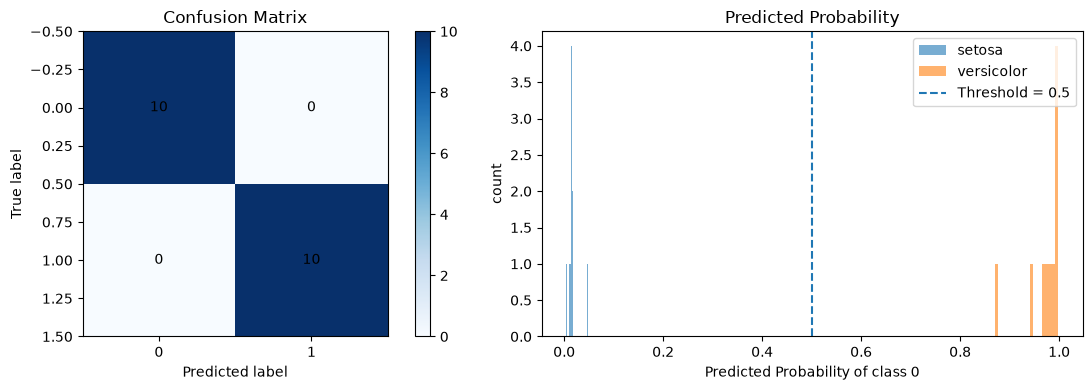

In [68]:
model.eval()

y_true_all =[]
y_prob_all =[]

with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))
        y_prob_all.append(y_hat.numpy().reshape(-1))

y_true = np.concatenate(y_true_all).astype(int)
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >= 0.5).astype(int)

cm = np.zeros((2,2), dtype=int)
for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

fig, axes = plt.subplots(1,2, figsize=(12,4))
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels=['0','1'])

for i in range(2):
    for j in range(2):
        axes[0].text(j,i,cm[i,j],ha='center', va='center')

fig.colorbar(im, ax=axes[0])

axes[1].hist(y_prob[y_true==0],bins=20, alpha=0.6, label='setosa')
axes[1].hist(y_prob[y_true==1],bins=20, alpha=0.6, label='versicolor')

axes[1].axvline(0.5, linestyle='--', label='Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()

plt.tight_layout()

plt.show()


#### STEP 6. 파라미터 개수 확인

In [69]:
# 층별 파라미터 수
layer1_params = sum(p.numel() for p in model.linear[0].parameters())
layer2_params = sum(p.numel() for p in model.linear[2].parameters())
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"입력층-은닉층 파라미터: {layer1_params:,}")
print(f"은닉층-출력층 파라미터: {layer2_params:,}")
print(f"전체 학습 가능 파라미터: {total_params:,}")

입력층-은닉층 파라미터: 500
은닉층-출력층 파라미터: 101
전체 학습 가능 파라미터: 601
